In [ ]:
import pandas as pd

In [ ]:
PATH = '/History_32026-05-19T11-46-10-920(in).csv'

In [ ]:
df = pd.read_csv(PATH, sep=';', header=2)
display(df.head())

,Unnamed: 0,Byte[],Byte[].1,Double,Double.1,Double.2,Double.3,Double.4,Double.5
0,2026-05-19T11:46:10.921,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.04,0.0,34
1,2026-05-19T11:46:11.290,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.04,0.0,34
2,2026-05-19T11:46:14.920,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 3, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.04,0.0,34
3,2026-05-19T11:46:15.296,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 3, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.03,0.0,34
4,2026-05-19T11:46:21.919,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.03,0.0,34


In [ ]:
new_column_names = [
    'Timestamp',
    'Port 1 PDI Data',
    'Port 2 PDI Data',
    'VELOCIDADE MOTOR 1',
    'ACELERAÇÃO MOTOR 1',
    'TEMPERATURA MOTOR 1',
    'VELOCIDADE MOTOR 2',
    'ACELERAÇÃO MOTOR 2',
    'TEMPERATURA MOTOR 2',
]
df.columns = new_column_names

# Drop the first row as it contains the human-readable headers that were just used
df = df.drop(df.index[0])

display(df.head())

,Timestamp,Port 1 PDI Data,Port 2 PDI Data,VELOCIDADE MOTOR 1,ACELERAÇÃO MOTOR 1,TEMPERATURA MOTOR 1,VELOCIDADE MOTOR 2,ACELERAÇÃO MOTOR 2,TEMPERATURA MOTOR 2
2,2026-05-19T11:46:14.920,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 3, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.04,0.0,34
3,2026-05-19T11:46:15.296,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 3, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.03,0.0,34
4,2026-05-19T11:46:21.919,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.03,0.0,34
5,2026-05-19T11:46:22.305,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.04,0.0,34
6,2026-05-19T11:46:28.919,"0, 4, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 27, 1, 0","0, 3, 100, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 34, 1, 0",0.04,0.0,27,0.04,0.0,34


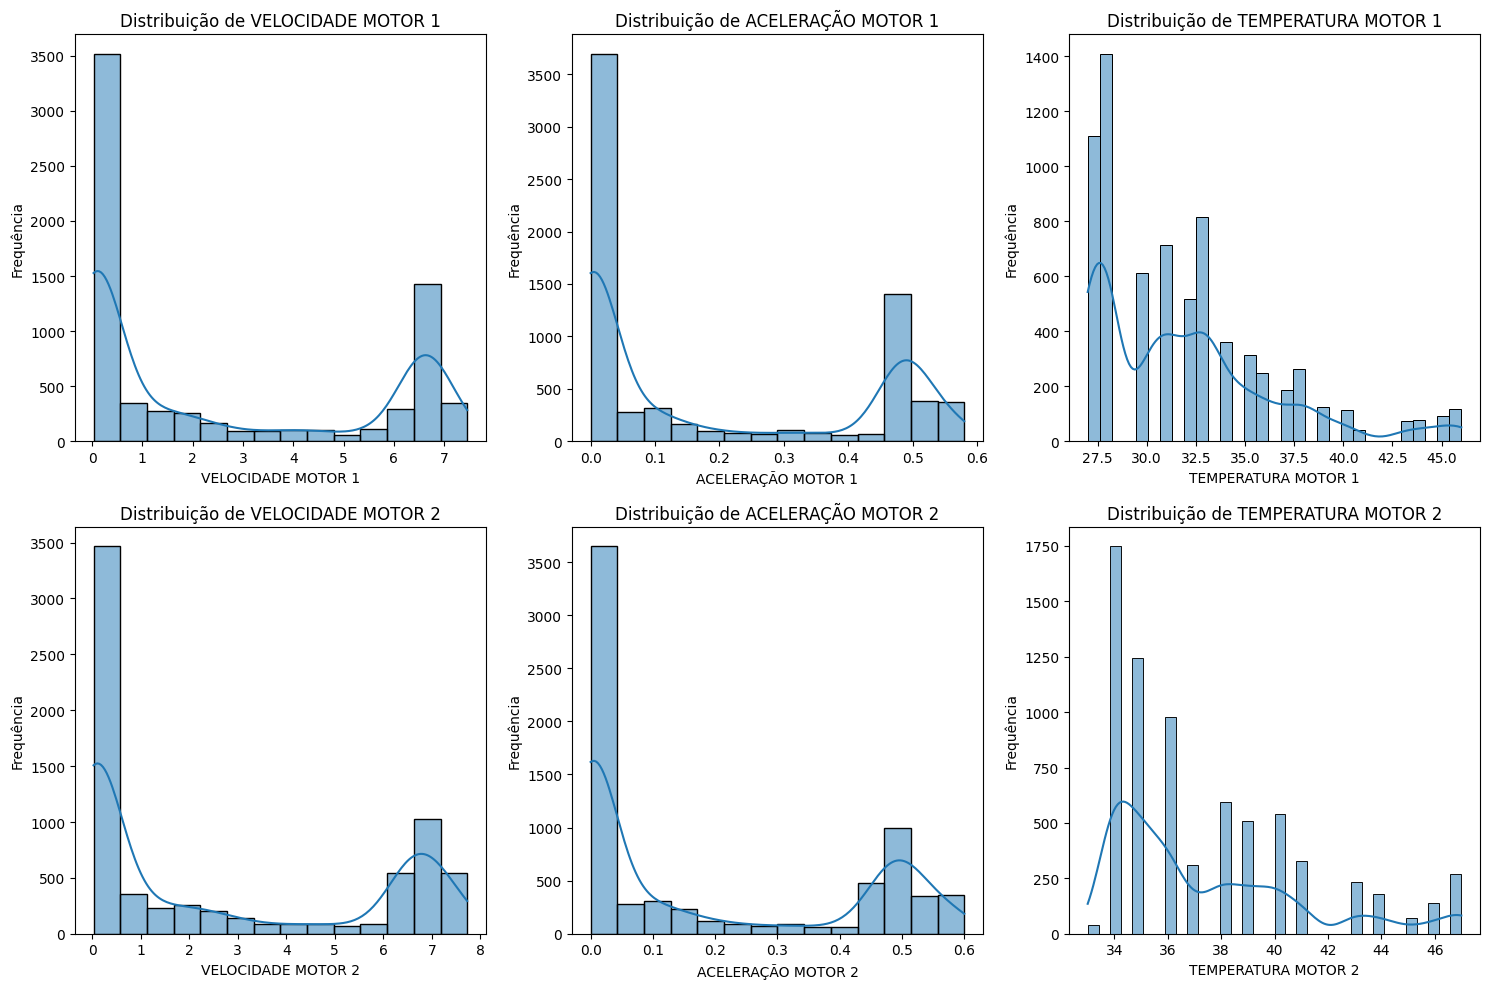

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert relevant columns to numeric, coercing errors to NaN
motor_columns = [
    'VELOCIDADE MOTOR 1',
    'ACELERAÇÃO MOTOR 1',
    'TEMPERATURA MOTOR 1',
    'VELOCIDADE MOTOR 2',
    'ACELERAÇÃO MOTOR 2',
    'TEMPERATURA MOTOR 2',
]

for col in motor_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with NaN values that resulted from conversion errors, if any
df_numeric = df.dropna(subset=motor_columns)

# Plotting the distributions
plt.figure(figsize=(15, 10))
for i, col in enumerate(motor_columns):
    plt.subplot(2, 3, i + 1) # 2 rows, 3 columns
    sns.histplot(df_numeric[col], kde=True)
    plt.title(f'Distribuição de {col}')
    plt.xlabel(col)
    plt.ylabel('Frequência')
plt.tight_layout()
plt.show()